# Dynamic programming: implementation

Iterative policy evaluation, policy improvement, policy iteration, value iteration and asynchronous backups on the chapter's three examples (small gridworld, Jack's car rental, the gambler's problem), checked against exact solutions.
Companion to the chapter note: [Dynamic programming](../chapters/04%20Dynamic%20programming.md).

**Sections**
1. A finite Markov decision process as arrays, and the backup operators
2. Iterative policy evaluation on the small gridworld
3. Policy improvement
4. Jack's car rental: policy iteration and value iteration
5. The gambler's problem: value iteration
6. Asynchronous dynamic programming
7. Generalized policy iteration
8. Checkpoints

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import poisson

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_STEPS, SEED_ASYNC = 41, 42  # one seed per section that draws random numbers
THETA = 1e-10  # stopping threshold for the sweeps that produce the "converged" values
THETA_COARSE = 1e-4  # threshold when counting sweeps to convergence
TIE_TOL = 1e-7  # actions within this of the best count as tied maximizers
TIE_TOLS = (1e-9, 1e-7, 1e-5)  # tolerances tried to show the tied set does not depend on the choice
AGREE_TOL = 1e-8  # two computations of the same value function must agree this closely
RESIDUAL_TOL = 1e-8  # Bellman residual at which the asynchronous comparison stops
BOOK_TOL = 0.051  # the book prints one decimal, so a grid entry can be off by 0.05 from rounding or truncation
Z_MAX = 4  # standard errors allowed between a simulated mean and its exact value
SMALL_ERROR, POLICY_GAP_TOL = 0.01, 1e-6  # value error and policy gap that count as "reached" in section 7
GRID_SIDE = 4
GRID_MOVES = ((-1, 0), (1, 0), (0, 1), (0, -1))  # up, down, right, left
GRID_ARROWS = "↑↓→←"
CAP = 20  # most cars at one location
MAX_MOVE = 5  # most cars moved overnight
RENT_PRICE, MOVE_COST, GAMMA_JACK = 10.0, 2.0, 0.9
RENT_RATE = (3, 4)  # Poisson means of rental requests at the first and second location
RETURN_RATE = (3, 2)  # Poisson means of returns
GOAL = 100
P_HEADS = (0.4, 0.25, 0.55)  # the first is the chapter's; the others make the problem harder and easier
SNAPSHOT_SWEEPS = (1, 2, 3, 10)  # value sweeps shown for the gambler's problem
RANDOM_G = np.full((GRID_SIDE**2, 4), 0.25)  # equiprobable random policy on the gridworld
BOOK_GRIDS = {  # the value grids printed in the book, one decimal
    1: [[0, -1, -1, -1], [-1, -1, -1, -1], [-1, -1, -1, -1], [-1, -1, -1, 0]],
    2: [[0, -1.7, -2, -2], [-1.7, -2, -2, -2], [-2, -2, -2, -1.7], [-2, -2, -1.7, 0]],
    3: [[0, -2.4, -2.9, -3], [-2.4, -2.9, -3, -2.9], [-2.9, -3, -2.9, -2.4], [-3, -2.9, -2.4, 0]],
    10: [[0, -6.1, -8.4, -9], [-6.1, -7.7, -8.4, -8.4], [-8.4, -8.4, -7.7, -6.1], [-9, -8.4, -6.1, 0]],
    "limit": [[0, -14, -20, -22], [-14, -18, -20, -20], [-20, -20, -18, -14], [-22, -20, -14, 0]],
}
STARTS, N_EPISODES = (1, 5, 3), 20_000  # start cells and episodes per start cell in section 2
N_RANDOM_RUNS = 5  # repeated runs of the random-state scheme in section 6
GPI_M, MAX_SWEEPS = (1, 3, 10, 50), 400  # evaluation sweeps per round and the sweep budget in section 7

## 1. A finite Markov decision process as arrays, and the backup operators

Dynamic programming (DP) needs a perfect model: for every state $s$ and action $a$, the probability $p(s',r \mid s,a)$ of each next state and reward.
For the problems here the reward depends only on $(s,a)$ in expectation, so the model is two arrays:

- `P[s, a, s']`, the probability of moving to $s'$ after taking $a$ in $s$;
- `R[s, a]`, the expected reward $\sum_{s',r} p(s',r \mid s,a)\, r$ of that step;
- `valid[s, a]`, which actions are allowed in a state (the action set $\mathcal{A}(s)$ differs by state in two of the examples).

A **policy** $\pi(a \mid s)$ is the probability of taking $a$ in $s$; $v_\pi$ is the **value function** of $\pi$ (the expected discounted sum of future rewards from each state) and $v_*$ the **optimal value function** (the best $v_\pi$ over all policies, in every state at once).
A terminal state is a state with one action that returns to itself with reward 0 and value 0, so every sweep can run over all states.

Every method below is built from one **backup**, the Bellman equation turned into an assignment that uses all successor states weighted by their probabilities (a full backup):

$$
q(s,a) = \sum_{s',r} p(s',r \mid s,a)\big[r + \gamma V(s')\big], \qquad
\underbrace{V(s) \leftarrow \sum_a \pi(a \mid s)\, q(s,a)}_{\text{policy evaluation}}, \qquad
\underbrace{V(s) \leftarrow \max_a q(s,a)}_{\text{value iteration}}
$$

- $V$ is the current estimate of a value function, $\gamma$ the discount rate and $q(s,a)$ the one-step lookahead value of taking $a$ in $s$.
- A **sweep** backs up every state once. The **two-array** version computes the new values from an untouched copy of the old ones; the **in-place** version overwrites each value at once, so later states in the same sweep already see the new values.
- The book's algorithm boxes are in place. The code below defaults to two-array for evaluation and value iteration, because the book's value grids after $k$ sweeps are defined by the two-array recursion $v_k \to v_{k+1}$. Sweep counts such as those in section 4 therefore depend on this choice; section 6 compares the two versions.
- The largest change in a sweep, $\Delta$, is compared with a small threshold $\theta$ to decide when to stop.
- The **Bellman residual** $\max_s \lvert \max_a q(s,a) - V(s) \rvert$ is zero exactly at the optimal value function, so it serves as a truth check that needs no reference answer.

In [2]:
def q_values(V: np.ndarray, P: np.ndarray, R: np.ndarray, gamma: float) -> np.ndarray:
    """One-step lookahead q(s, a) of every state-action pair under the value estimate `V`."""
    return R + gamma * (P @ V)


def optimal_backup(V, P, R, valid, gamma) -> np.ndarray:
    """Value-iteration backup of every state: the best valid action's q."""
    return np.where(valid, q_values(V, P, R, gamma), -np.inf).max(axis=1)


def bellman_residual(V, P, R, valid, gamma) -> float:
    """Largest gap between `V` and its own max-backup; zero only at the optimal value function."""
    return float(np.abs(optimal_backup(V, P, R, valid, gamma) - V).max())


def evaluate_policy(P: np.ndarray, R: np.ndarray, pi: np.ndarray, gamma: float, theta: float, in_place: bool = False, order: np.ndarray | None = None, V0: np.ndarray | None = None, max_sweeps: int | None = None) -> tuple[np.ndarray, int]:
    """Iterative policy evaluation of the stochastic policy `pi[s, a]`; returns (V, sweeps), stopping when the largest change is below `theta` or after `max_sweeps`."""
    P_pi, R_pi = np.einsum("sa,sat->st", pi, P), (pi * R).sum(axis=1)
    V = np.zeros(len(R)) if V0 is None else V0.copy()
    order = np.arange(len(R)) if order is None else order
    sweeps = 0
    while True:
        old = V.copy()
        if in_place:
            for s in order:
                V[s] = R_pi[s] + gamma * P_pi[s] @ V
        else:
            V = R_pi + gamma * P_pi @ old
        sweeps += 1
        if np.abs(V - old).max() < theta or sweeps == max_sweeps:
            return V, sweeps


def solve_policy(P, R, pi, gamma, nonterminal):
    """Exact v_pi from the linear Bellman equations, restricted to the nonterminal states (terminal values are 0)."""
    P_pi, R_pi = np.einsum("sa,sat->st", pi, P), (pi * R).sum(axis=1)
    V, idx = np.zeros(len(R)), np.flatnonzero(nonterminal)
    V[idx] = np.linalg.solve(np.eye(len(idx)) - gamma * P_pi[np.ix_(idx, idx)], R_pi[idx])
    return V

In [3]:
def backup_state(s, V, P, R, valid, gamma) -> float:
    """Value-iteration backup of the single state `s`."""
    return np.where(valid[s], R[s] + gamma * P[s] @ V, -np.inf).max()


def value_iteration(P: np.ndarray, R: np.ndarray, valid: np.ndarray, gamma: float, theta: float, in_place: bool = False, order: np.ndarray | None = None, V0: np.ndarray | None = None, snapshots: tuple = ()) -> tuple[np.ndarray, int, dict]:
    """Value iteration; returns (V, sweeps, {sweep: V copy for each sweep in `snapshots`})."""
    V = np.zeros(len(R)) if V0 is None else V0.copy()
    order = np.arange(len(R)) if order is None else order
    sweeps, snaps = 0, {}
    while True:
        old = V.copy()
        if in_place:
            for s in order:
                V[s] = backup_state(s, V, P, R, valid, gamma)
        else:
            V = optimal_backup(old, P, R, valid, gamma)
        sweeps += 1
        if sweeps in snapshots:
            snaps[sweeps] = V.copy()
        if np.abs(V - old).max() < theta:
            return V, sweeps, snaps

## 2. Iterative policy evaluation on the small gridworld

Fourteen nonterminal cells in a four-by-four grid; the top-left and bottom-right corner cells together form the terminal state.
Four actions (up, down, right, left) move deterministically, except that a move off the grid leaves the agent where it is.
The task is undiscounted ($\gamma = 1$), episodic, with reward $-1$ on every step until the terminal state is reached.
We evaluate the equiprobable random policy, $\pi(a \mid s) = 1/4$ for every action.

Cells are numbered row by row from 0 and the nonterminal cells are 1 to 14. The two corners form one terminal state in the book; the arrays keep them as two absorbing cells, 0 and 15, which have value 0 and are never a problem for the sweeps.
Evaluation uses the policy-evaluation backup from the previous section with $V$ started at zero.

Because every step costs 1 until the episode ends, the limit $v_\pi(s)$ is the negative of the expected number of steps from $s$ to termination; we check that with simulated episodes.

In [4]:
def gridworld() -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Model arrays of the small gridworld: (P, R, valid) with the two terminal corners absorbing."""
    n = GRID_SIDE**2
    P, R = np.zeros((n, 4, n)), -np.ones((n, 4))
    for s in range(n):
        r, c = divmod(s, GRID_SIDE)
        for a, (dr, dc) in enumerate(GRID_MOVES):
            nr, nc = r + dr, c + dc
            inside = 0 <= nr < GRID_SIDE and 0 <= nc < GRID_SIDE
            P[s, a, nr * GRID_SIDE + nc if inside else s] = 1.0
    for s in (0, n - 1):
        P[s], R[s] = 0.0, 0.0
        P[s, :, s] = 1.0
    return P, R, np.ones((n, 4), bool)


def show_grid(V: np.ndarray) -> str:
    """Value grid as text, two decimals."""
    return "\n".join(" ".join(f"{v:6.2f}" for v in row) for row in V.reshape(GRID_SIDE, GRID_SIDE))


P_G, R_G, VALID_G = gridworld()
NONTERMINAL_G = np.ones(GRID_SIDE**2, bool)
NONTERMINAL_G[[0, -1]] = False

In [5]:
grid_values, V = {}, np.zeros(16)
for k in range(1, 11):
    V, _ = evaluate_policy(P_G, R_G, RANDOM_G, 1.0, theta=THETA, V0=V, max_sweeps=1)
    if k in (1, 2, 3, 10):
        grid_values[k] = V
        print(f"v_{k}:\n{show_grid(V)}\n")
grid_values["limit"], sweeps_limit = evaluate_policy(P_G, R_G, RANDOM_G, 1.0, THETA)
print(f"v_pi after {sweeps_limit} sweeps (largest change below {THETA}):\n{show_grid(grid_values['limit'])}")

gaps = {k: np.abs(grid_values[k].reshape(4, 4) - np.array(BOOK_GRIDS[k])).max() for k in grid_values}
print("Largest difference to the book's printed grid:", {k: round(float(g), 3) for k, g in gaps.items()})
print(f"Checkpoint: every grid is within {BOOK_TOL} of the book's grid (one decimal printed, so entries are off by at most 0.05; the book shows -1.75 as -1.7):", all(g < BOOK_TOL for g in gaps.values()))
exact_G = solve_policy(P_G, R_G, RANDOM_G, 1.0, NONTERMINAL_G)
print(f"Checkpoint: limit of the sweeps vs exact linear solve, largest difference {np.abs(grid_values['limit'] - exact_G).max():.2e}")

v_1:
  0.00  -1.00  -1.00  -1.00
 -1.00  -1.00  -1.00  -1.00
 -1.00  -1.00  -1.00  -1.00
 -1.00  -1.00  -1.00   0.00

v_2:
  0.00  -1.75  -2.00  -2.00
 -1.75  -2.00  -2.00  -2.00
 -2.00  -2.00  -2.00  -1.75
 -2.00  -2.00  -1.75   0.00

v_3:
  0.00  -2.44  -2.94  -3.00
 -2.44  -2.88  -3.00  -2.94
 -2.94  -3.00  -2.88  -2.44
 -3.00  -2.94  -2.44   0.00

v_10:
  0.00  -6.14  -8.35  -8.97
 -6.14  -7.74  -8.43  -8.35
 -8.35  -8.43  -7.74  -6.14
 -8.97  -8.35  -6.14   0.00

v_pi after 426 sweeps (largest change below 1e-10):
  0.00 -14.00 -20.00 -22.00
-14.00 -18.00 -20.00 -20.00
-20.00 -20.00 -18.00 -14.00
-22.00 -20.00 -14.00   0.00
Largest difference to the book's printed grid: {1: 0.0, 2: 0.05, 3: 0.038, 10: 0.048, 'limit': 0.0}
Checkpoint: every grid is within 0.051 of the book's grid (one decimal printed, so entries are off by at most 0.05; the book shows -1.75 as -1.7): True
Checkpoint: limit of the sweeps vs exact linear solve, largest difference 1.73e-09


### Reading the result

- After one sweep every nonterminal cell has $-1$ (the reward of one step); after two, the cells next to a terminal corner have $-1.75$ and the others $-2$.
- The grids at $k = 3$ and $k = 10$ keep growing in magnitude (from $-3.00$ to $-8.97$ at the farthest cell), and the limit, reached after 426 sweeps, is $-14$, $-18$, $-20$ and $-22$ across the cell types.
- The limit agrees with the exact linear solve to $1.7 \times 10^{-9}$, which is the stopping threshold at work.
- Against the grids printed in the book the largest difference is 0.05 (at $k = 2$), 0.038 ($k = 3$), 0.048 ($k = 10$) and 0 at $k = 1$ and in the limit. The book prints one decimal and shows $-1.75$ as $-1.7$, so every grid agrees to its printed precision (the checkpoint tolerance is 0.051, the rounding half-width of the printed decimal).

In [6]:
def simulate_steps(starts, n_episodes: int, rng) -> np.ndarray:
    """Steps to termination of `n_episodes` random-policy episodes from each start cell; shape (len(starts), n_episodes)."""
    next_cell = P_G.argmax(axis=2)
    cell = np.repeat(np.asarray(starts)[:, None], n_episodes, axis=1)
    steps = np.zeros_like(cell)
    active = np.isin(cell, np.flatnonzero(NONTERMINAL_G))
    while active.any():
        cell = np.where(active, next_cell[cell, rng.integers(4, size=cell.shape)], cell)
        steps += active
        active = np.isin(cell, np.flatnonzero(NONTERMINAL_G))
    return steps


rng = np.random.default_rng(SEED_STEPS)
steps = simulate_steps(STARTS, N_EPISODES, rng)
for s, row in zip(STARTS, steps):
    print(f"cell {s:2d}: mean steps {row.mean():6.2f} +- {row.std(ddof=1) / np.sqrt(N_EPISODES):.2f} (standard error), -v_pi = {-exact_G[s]:.2f}")
z = [(row.mean() + exact_G[s]) / (row.std(ddof=1) / np.sqrt(N_EPISODES)) for s, row in zip(STARTS, steps)]
print(f"Checkpoint: simulated mean steps within {Z_MAX} standard errors of -v_pi:", all(abs(v) < Z_MAX for v in z))

cell  1: mean steps  13.94 +- 0.12 (standard error), -v_pi = 14.00
cell  5: mean steps  17.92 +- 0.13 (standard error), -v_pi = 18.00
cell  3: mean steps  21.87 +- 0.13 (standard error), -v_pi = 22.00
Checkpoint: simulated mean steps within 4 standard errors of -v_pi: True


### Reading the result

- From 20,000 simulated random-policy episodes per start cell, the mean number of steps is 13.94, 17.92 and 21.87 (standard error about 0.12 to 0.13) for cells 1, 5 and 3, against $-v_\pi$ of 14, 18 and 22.
- So the converged values are indeed the negated expected number of steps to termination; the three simulated means are within about one standard error of that value.

## 3. Policy improvement

Given $v_\pi$, the question is whether some other action in a state beats what $\pi$ does.
The **greedy** policy looks one step ahead with the current values and picks the best action:

$$
\pi'(s) = \arg\max_a \sum_{s',r} p(s',r \mid s,a)\big[r + \gamma v_\pi(s')\big]
$$

- The policy improvement theorem says $\pi'$ is at least as good as $\pi$ in every state, and strictly better somewhere unless $\pi$ is already optimal.
- When several actions tie for the maximum, any split of the probability among them is allowed; the code splits it equally.

Here we make the policy greedy with respect to each approximation $v_k$ from the previous section, and test whether it is already optimal by computing its exact value and comparing with the optimal value function $v_*$ (found with value iteration).

In [7]:
def greedy_mask(Q: np.ndarray, valid: np.ndarray, tol: float = TIE_TOL) -> np.ndarray:
    """Boolean mask of the valid actions whose q is within `tol` of the best in each state."""
    Qv = np.where(valid, Q, -np.inf)
    return Qv >= Qv.max(axis=1, keepdims=True) - tol


def greedy_policy(V, P, R, valid, gamma) -> np.ndarray:
    """Stochastic policy that splits probability equally over the greedy actions."""
    mask = greedy_mask(q_values(V, P, R, gamma), valid)
    return mask / mask.sum(axis=1, keepdims=True)


def arrow_grid(pi: np.ndarray) -> str:
    """The greedy actions of each gridworld cell as arrows."""
    cells = ["T" if s in (0, 15) else "".join(GRID_ARROWS[a] for a in np.flatnonzero(pi[s] > 0)) for s in range(16)]
    return "\n".join(" ".join(f"{c:>4}" for c in cells[r * 4 : r * 4 + 4]) for r in range(4))

In [8]:
V_STAR_G, _, _ = value_iteration(P_G, R_G, VALID_G, 1.0, THETA)
optimal_after = {}
for k in (0, 1, 2, 3, 10):
    V_k = np.zeros(16) if k == 0 else grid_values[k]
    pi_k = greedy_policy(V_k, P_G, R_G, VALID_G, 1.0)
    v_pi_k = solve_policy(P_G, R_G, pi_k, 1.0, NONTERMINAL_G)
    optimal_after[k] = bool(np.abs(v_pi_k - V_STAR_G).max() < AGREE_TOL)
    print(f"Greedy policy for v_{k} (arrows = all maximizing actions), optimal: {optimal_after[k]}\n{arrow_grid(pi_k)}\n")

pi_improved = greedy_policy(exact_G, P_G, R_G, VALID_G, 1.0)
v_improved = solve_policy(P_G, R_G, pi_improved, 1.0, NONTERMINAL_G)
print("Greedy policy for the exact v_pi: value of every cell at least as high as under the random policy:", bool((v_improved >= exact_G - 1e-12).all()))
improved_is_optimal = bool(np.abs(v_improved - V_STAR_G).max() < AGREE_TOL)
print("Checkpoint: one improvement step from the exact random-policy values already gives an optimal policy:", improved_is_optimal)
print(f"Checkpoint: optimal value of the farthest cell is {V_STAR_G[3]:.1f}, the random policy's is {exact_G[3]:.1f}")

Greedy policy for v_0 (arrows = all maximizing actions), optimal: False
   T ↑↓→← ↑↓→← ↑↓→←
↑↓→← ↑↓→← ↑↓→← ↑↓→←
↑↓→← ↑↓→← ↑↓→← ↑↓→←
↑↓→← ↑↓→← ↑↓→←    T

Greedy policy for v_1 (arrows = all maximizing actions), optimal: False
   T    ← ↑↓→← ↑↓→←
   ↑ ↑↓→← ↑↓→← ↑↓→←
↑↓→← ↑↓→← ↑↓→←    ↓
↑↓→← ↑↓→←    →    T

Greedy policy for v_2 (arrows = all maximizing actions), optimal: False
   T    ←    ← ↑↓→←
   ↑   ↑← ↑↓→←    ↓
   ↑ ↑↓→←   ↓→    ↓
↑↓→←    →    →    T

Greedy policy for v_3 (arrows = all maximizing actions), optimal: True
   T    ←    ←   ↓←
   ↑   ↑←   ↓←    ↓
   ↑   ↑→   ↓→    ↓
  ↑→    →    →    T

Greedy policy for v_10 (arrows = all maximizing actions), optimal: True
   T    ←    ←   ↓←
   ↑   ↑←   ↓←    ↓
   ↑   ↑→   ↓→    ↓
  ↑→    →    →    T

Greedy policy for the exact v_pi: value of every cell at least as high as under the random policy: True
Checkpoint: one improvement step from the exact random-policy values already gives an optimal policy: True
Checkpoint: optimal value

### Reading the result

- With all values equal, every action ties, so the greedy policy for $v_0$ is the random policy itself and is not optimal.
- For $v_1$ only the cells beside a terminal corner single out a move; for $v_2$ more cells do, and neither policy is optimal yet.
- The greedy policy for $v_3$ is optimal, and so is the one for $v_{10}$ (the same arrows). The policies after the third approximation are optimal, as in the book.
- Where two arrows are shown (for example cell 5, up or left) both actions are equally good, so the optimal policy is not unique here either.
- One improvement step from the exact random-policy values already gives an optimal policy, and the improvement theorem holds: no cell gets worse.
- The farthest cell is worth $-3.0$ under the optimal policy and $-22.0$ under the random one.

## 4. Jack's car rental: policy iteration and value iteration

Jack runs two rental locations. Each day customers ask for cars at each location; a rented car earns \$10, and a request with no car available is lost.
Returns are independent Poisson counts, and a returned car can be rented from the following day.
Overnight Jack can move at most 5 cars from one location to the other, at \$2 per car.
Each location holds at most 20 cars; surplus cars disappear from the problem, whether they were returned or moved into a full location, and moving them still costs 2 dollars.
Requests and returns are Poisson distributed: the means are 3 and 4 for requests at the first and second location and 3 and 2 for returns.
The discount rate is $\gamma = 0.9$.

- **State**: the number of cars at each location at the end of the day, $21 \times 21 = 441$ states.
- **Action**: the net number of cars moved overnight from the first to the second location, from $-5$ to $5$ (negative means the other direction), limited by the cars present. After the move, rentals and returns of the next day happen.
- **Reward**: 10 dollars per car rented the next day, minus 2 dollars per car moved.

The model is built once. Requests and returns at the two locations are independent, so the transition probability is a product of per-location tables.
The Poisson tails need no truncation: a request count beyond the cars on hand rents every car, and a return count beyond the capacity fills the location, so the tail probabilities are folded into the last outcome and the tables are exact.

**Policy iteration** alternates two steps until the policy stops changing:

$$
\pi_0 \xrightarrow{\text{evaluate}} v_{\pi_0} \xrightarrow{\text{improve}} \pi_1 \xrightarrow{\text{evaluate}} v_{\pi_1} \xrightarrow{\text{improve}} \cdots \to \pi_*, v_*
$$

Each evaluation starts from the previous policy's values, which are already close.
Tie rule: an action counts as best when its value is within `TIE_TOL` ($10^{-7}$) of the maximum, and the improvement keeps the current action whenever it is still best, so two equally good policies cannot flip back and forth forever.
The book's box uses a plain argmax and the test $a \neq \pi(s)$ instead, so the number of improvements and of changed states reported below depend on this tie rule.
Both methods use the two-array version of evaluation and of the max-backup.

In [9]:
def tail_pmf(rate: float, n: int) -> np.ndarray:
    """Poisson probabilities of 0..n-1 and, in the last entry, of n or more."""
    p = poisson.pmf(np.arange(n + 1), rate)
    p[n] = poisson.sf(n - 1, rate)
    return p


def location_model(rent_rate: float, return_rate: float):
    """One location: T[m, n'] = P(evening cars n' | m cars in the morning) and the expected rental income given m."""
    T, income = np.zeros((CAP + 1, CAP + 1)), np.zeros(CAP + 1)
    returned = tail_pmf(return_rate, CAP)
    for m in range(CAP + 1):
        rented = tail_pmf(rent_rate, m)
        income[m] = RENT_PRICE * rented @ np.arange(m + 1)
        evening = np.minimum(CAP, (m - np.arange(m + 1))[:, None] + np.arange(CAP + 1)[None, :])
        np.add.at(T[m], evening.ravel(), (rented[:, None] * returned[None, :]).ravel())
    return T, income


def jack_model():
    """(P, R, valid) over states n1 * 21 + n2 and actions 0..10 meaning moves -5..5."""
    (T1, income1), (T2, income2) = (location_model(rent, back) for rent, back in zip(RENT_RATE, RETURN_RATE))
    n = CAP + 1
    n1, n2, move = np.meshgrid(np.arange(n), np.arange(n), np.arange(-MAX_MOVE, MAX_MOVE + 1), indexing="ij")
    m1, m2 = np.clip(n1 - move, 0, CAP), np.clip(n2 + move, 0, CAP)
    P = np.einsum("ab,cd->acbd", T1, T2)[m1, m2].reshape(n * n, -1, n * n)
    R = (income1[m1] + income2[m2] - MOVE_COST * np.abs(move)).reshape(n * n, -1)
    return P, R, ((move <= n1) & (-move <= n2)).reshape(n * n, -1)

In [10]:
def policy_iteration(P: np.ndarray, R: np.ndarray, valid: np.ndarray, gamma: float, theta: float, start_actions: np.ndarray) -> tuple[list, np.ndarray, list]:
    """Policy iteration from a deterministic policy of action indices; returns (policies, V, evaluation sweeps per iteration)."""
    rows, acts, V = np.arange(len(R)), start_actions.copy(), np.zeros(len(R))
    policies, sweeps = [acts], []
    while True:
        V, n = evaluate_policy(P, R, np.eye(R.shape[1])[acts], gamma, theta, V0=V)
        sweeps.append(n)
        best = greedy_mask(q_values(V, P, R, gamma), valid)
        new = np.where(best[rows, acts], acts, best.argmax(axis=1))
        if (new == acts).all():
            return policies, V, sweeps
        acts = new
        policies.append(acts)


P_J, R_J, VALID_J = jack_model()
print(f"Model arrays: P {P_J.shape}, rows sum to one: {np.allclose(P_J[VALID_J].sum(axis=-1), 1.0)}")

Model arrays: P (441, 11, 441), rows sum to one: True


In [11]:
policies_J, V_PI_J, eval_sweeps_J = policy_iteration(P_J, R_J, VALID_J, GAMMA_JACK, THETA, np.full(441, MAX_MOVE))
V_VI_J, sweeps_vi_J, _ = value_iteration(P_J, R_J, VALID_J, GAMMA_JACK, THETA)
print(f"Policy iteration: {len(policies_J) - 1} improvements, evaluation sweeps per iteration {eval_sweeps_J} (total {sum(eval_sweeps_J)})")
print("States whose action changed at each improvement:", [int((a != b).sum()) for a, b in zip(policies_J, policies_J[1:])])
print(f"Value iteration: {sweeps_vi_J} sweeps")
V_NEVER_MOVE, _ = evaluate_policy(P_J, R_J, np.eye(11)[policies_J[0]], GAMMA_JACK, THETA)
print(f"Value of the never-move policy ranges from {V_NEVER_MOVE.min():.1f} to {V_NEVER_MOVE.max():.1f}")
cars_at_min, cars_at_max = (tuple(int(c) for c in np.unravel_index(i, (21, 21))) for i in (V_PI_J.argmin(), V_PI_J.argmax()))
print(f"Optimal value ranges from {V_PI_J.min():.1f} (cars {cars_at_min}) to {V_PI_J.max():.1f} (cars {cars_at_max})")
print(f"Final policy moves between {policies_J[-1].min() - MAX_MOVE} and {policies_J[-1].max() - MAX_MOVE} cars")
gap_pi_vi = np.abs(V_PI_J - V_VI_J).max()
residual_pi = bellman_residual(V_PI_J, P_J, R_J, VALID_J, GAMMA_JACK)
print(f"Checkpoint: policy iteration and value iteration agree on v_*, largest difference {gap_pi_vi:.2e}")
print(f"Checkpoint: Bellman residual of the policy-iteration values is {residual_pi:.2e}")
q_star_J = q_values(V_PI_J, P_J, R_J, GAMMA_JACK)
vi_actions = greedy_mask(q_values(V_VI_J, P_J, R_J, GAMMA_JACK), VALID_J).argmax(axis=1)
print(f"Value iteration's greedy policy differs from policy iteration's in {int((vi_actions != policies_J[-1]).sum())} states, but loses at most {np.abs(V_PI_J - q_star_J[np.arange(441), vi_actions]).max():.1e} in q (ties)")

Policy iteration: 4 improvements, evaluation sweeps per iteration [257, 223, 211, 176, 103] (total 970)
States whose action changed at each improvement: [318, 272, 79, 8]
Value iteration: 257 sweeps
Value of the never-move policy ranges from 407.2 to 611.4
Optimal value ranges from 421.4 (cars (0, 0)) to 637.0 (cars (20, 20))
Final policy moves between -4 and 5 cars
Checkpoint: policy iteration and value iteration agree on v_*, largest difference 2.43e-11
Checkpoint: Bellman residual of the policy-iteration values is 8.25e-11
Value iteration's greedy policy differs from policy iteration's in 0 states, but loses at most 8.3e-11 in q (ties)


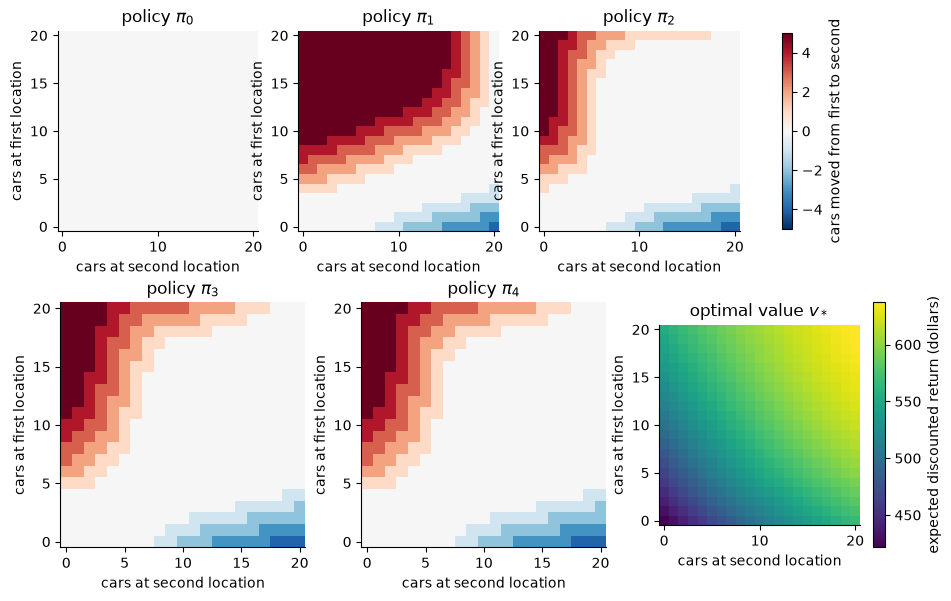

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, (i, acts) in zip(axes.ravel(), enumerate(policies_J)):
    im = ax.imshow(acts.reshape(21, 21) - MAX_MOVE, origin="lower", cmap="RdBu_r", vmin=-5, vmax=5)
    ax.set(title=f"policy $\\pi_{i}$", xlabel="cars at second location", ylabel="cars at first location")
fig.colorbar(im, ax=axes[0, :], label="cars moved from first to second", shrink=0.8)
v_im = axes[1, 2].imshow(V_PI_J.reshape(21, 21), origin="lower", cmap="viridis")
axes[1, 2].set(title="optimal value $v_*$", xlabel="cars at second location", ylabel="cars at first location")
fig.colorbar(v_im, ax=axes[1, 2], label="expected discounted return (dollars)")
for ax in axes.ravel():
    ax.grid(False)
plt.show()

### Reading the result

- Policy iteration needs 4 improvements, so five policies $\pi_0, \dots, \pi_4$ appear in the figure. The numbers of states whose action changed are 318, 272, 79 and 8.
- The first improvement already moves the maximum 5 cars from the first to the second location when the first has many cars and the second few, and moves cars the other way only when the second location is nearly full and the first nearly empty. Later policies refine the borders of these regions.
- Value iteration (257 sweeps) and policy iteration agree on $v_*$ to $2.4 \times 10^{-11}$, the Bellman residual is $8.3 \times 10^{-11}$, and the greedy policy of value iteration differs from the final policy in 0 states.
- Evaluation took 257, 223, 211, 176 and 103 sweeps in the five iterations (970 in total), fewer each time because each starts from the previous values, but still more than value iteration's 257 sweeps at this strict threshold.
- The never-move policy $\pi_0$ is worth 407.2 to 611.4.
- The final policy moves between $-4$ and $5$ cars, the same extremes as in the book's figure, with the same sign convention and the same regions.
- The book's value surface spans about 420 to 612 (it touches the corners of its plot box). We reproduce the minimum (421.4 with both locations empty) but not the maximum (637.0 with both full). The cause is not identified.
- A separate, independent re-solution of the same model gave the same 421.4 and 637.0, and tried these variants, none of which moves the maximum to 612 without moving the minimum away from 420: Poisson truncated at 11 or 12 (range 406 to 618 and 417 to 631), truncation of requests only, renormalized truncation (421 to 636), returns rentable the same day (466 to 646), one free car moved from the first to the second location (430 to 648), a 4-dollar parking fee above 10 cars (421 to 595), free car plus parking (430 to 604), a move cost of 1 dollar (427 to 644) and $\gamma = 0.89$ (378 to 585). These variants are not run in this notebook. The likely cause is a detail of the authors' own code or figure that the text does not state.
- The 4 improvements and the 318, 272, 79 and 8 changed states depend on the tie rule (within $10^{-7}$ counts as tied, keep the current action if it is still best); the book's plain argmax may move individual borders by a cell. The sweep counts (257, 970) depend on the two-array version of evaluation.

## 5. The gambler's problem: value iteration

A gambler bets on coin flips. With capital $s$ dollars (1 to 99) he stakes $a$ dollars, between 1 and $\min(s, 100 - s)$.
Heads, with probability $p_h$, adds the stake to his capital; tails removes it.
The episode ends at 0 dollars (a loss) or at 100 dollars (a win), the reward is $+1$ for reaching 100 and 0 otherwise, and there is no discounting.
So $v_*(s)$ is the largest probability of reaching the goal from capital $s$.

$$
V(s) \leftarrow \max_a \big[\, p_h\,(\mathbb{1}[s + a = 100] + V(s+a)) + (1 - p_h)\, V(s-a) \,\big]
$$

- $\mathbb{1}[\cdot]$ is 1 when the condition inside holds and 0 otherwise, so the reward $+1$ is collected exactly on the flip that reaches 100.
- The chapter lists a stake of 0 among the actions. It changes nothing, so its value equals $V(s)$ and it would tie with the best stake in every state at the fixed point; it is left out here so that ties show only real alternatives.
- Value iteration is run in place, state by state in increasing capital, as in the algorithm box, until the largest change in a sweep is below $\theta$; the output is a greedy policy.
- The same code is run for $p_h = 0.4$ (the chapter's case), $0.25$ (a game that is worse for the gambler) and $0.55$ (a favorable game).

In [13]:
def gambler_model(p_heads: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """(P, R, valid) over capital 0..100 and stake 0..50; the terminal capitals 0 and 100 only allow stake 0."""
    n, n_stakes = GOAL + 1, GOAL // 2 + 1
    P, R, valid = np.zeros((n, n_stakes, n)), np.zeros((n, n_stakes)), np.zeros((n, n_stakes), bool)
    for s in (0, GOAL):
        P[s, 0, s], valid[s, 0] = 1.0, True
    for s in range(1, GOAL):
        for a in range(1, min(s, GOAL - s) + 1):
            P[s, a, s + a], P[s, a, s - a], valid[s, a] = p_heads, 1 - p_heads, True
            R[s, a] = p_heads * (s + a == GOAL)
    return P, R, valid


GAMBLER = {p: gambler_model(p) for p in P_HEADS}
solved = {}
for p, (P_p, R_p, valid_p) in GAMBLER.items():
    V_p, sweeps_p, snaps_p = value_iteration(P_p, R_p, valid_p, 1.0, THETA, in_place=True, order=np.arange(1, GOAL), snapshots=SNAPSHOT_SWEEPS)
    optimal_stakes = greedy_mask(q_values(V_p, P_p, R_p, 1.0), valid_p)[1:GOAL]
    solved[p] = (V_p, sweeps_p, snaps_p, optimal_stakes)
    residual = bellman_residual(V_p, P_p, R_p, valid_p, 1.0)
    print(f"p_h = {p}: {sweeps_p} sweeps, v_*(50) = {V_p[50]:.4f}, v_*(1) = {V_p[1]:.4f}, Bellman residual {residual:.1e}")
V_4, _, snaps_4, stakes_4 = solved[0.4]
print("Optimal stakes at p_h = 0.4:", {s: np.flatnonzero(stakes_4[s - 1]).tolist() for s in (10, 20, 25, 50, 75)})
sweep1 = snaps_4[1]
print(f"Value after sweep 1: capital 49 {sweep1[49]:.2f}, 50 {sweep1[50]:.2f}, 74 {sweep1[74]:.2f}, 75 {sweep1[75]:.2f}, 99 {sweep1[99]:.2f}")
print(f"Final value at capital 1, 50 and 99: {V_4[1]:.3f}, {V_4[50]:.3f}, {V_4[99]:.3f}")
ties_by_tol = {tol: int((greedy_mask(q_values(V_4, *GAMBLER[0.4][:2], 1.0), GAMBLER[0.4][2], tol)[1:GOAL].sum(axis=1) > 1).sum()) for tol in TIE_TOLS}
print(f"States with tied optimal stakes for tie tolerance {TIE_TOLS}:", list(ties_by_tol.values()))
smallest_stake = stakes_4.argmax(axis=1)  # column index is the stake; argmax takes the first True
print(f"Smallest optimal stake: peaks at {smallest_stake[:24].max()} (capital {int(smallest_stake[:24].argmax()) + 1}) below capital 25; at capital 25 and 75 it is {smallest_stake[24]} and {smallest_stake[74]}")
print("Checkpoint: sweep 1 is 0 below capital 50, 0.4 from 50 up to 74 and 0.64 at 75:", bool(np.allclose(sweep1[1:50], 0) and np.allclose(sweep1[50:75], 0.4) and np.isclose(sweep1[75], 0.64)))
print("Checkpoint: the set of tied states does not depend on the tolerance:", len(set(ties_by_tol.values())) == 1)

p_h = 0.4: 19 sweeps, v_*(50) = 0.4000, v_*(1) = 0.0021, Bellman residual 1.9e-11
p_h = 0.25: 16 sweeps, v_*(50) = 0.2500, v_*(1) = 0.0001, Bellman residual 6.2e-12
p_h = 0.55: 1838 sweeps, v_*(50) = 1.0000, v_*(1) = 0.1818, Bellman residual 5.5e-11
Optimal stakes at p_h = 0.4: {10: [10], 20: [5, 20], 25: [25], 50: [50], 75: [25]}
Value after sweep 1: capital 49 0.00, 50 0.40, 74 0.40, 75 0.64, 99 0.95
Final value at capital 1, 50 and 99: 0.002, 0.400, 0.964
States with tied optimal stakes for tie tolerance (1e-09, 1e-07, 1e-05): [72, 72, 72]
Smallest optimal stake: peaks at 12 (capital 12) below capital 25; at capital 25 and 75 it is 25 and 25
Checkpoint: sweep 1 is 0 below capital 50, 0.4 from 50 up to 74 and 0.64 at 75: True
Checkpoint: the set of tied states does not depend on the tolerance: True


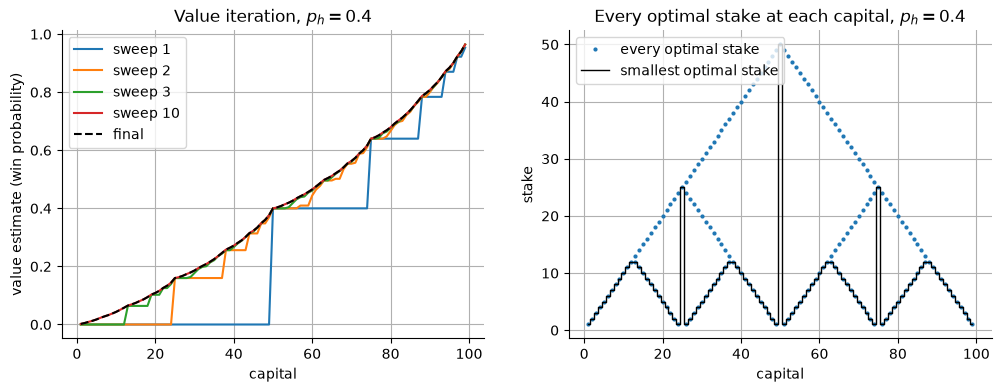

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sweep, V_s in snaps_4.items():
    axes[0].plot(range(1, GOAL), V_s[1:GOAL], label=f"sweep {sweep}")
axes[0].plot(range(1, GOAL), V_4[1:GOAL], "k--", label="final")
axes[0].set(xlabel="capital", ylabel="value estimate (win probability)", title="Value iteration, $p_h = 0.4$")
axes[0].legend()
caps, stakes = np.nonzero(stakes_4)
axes[1].plot(caps + 1, stakes, ".", ms=4, label="every optimal stake")
axes[1].step(range(1, GOAL), smallest_stake, where="mid", color="k", lw=1, label="smallest optimal stake")
axes[1].legend(loc="upper left")
axes[1].set(xlabel="capital", ylabel="stake", title="Every optimal stake at each capital, $p_h = 0.4$")
plt.show()

### Reading the result

- Value iteration needs 19 sweeps to settle at $p_h = 0.4$ (the book labels sweep 32 as close to final; ours is converged by then, so the plot shows sweep 10). After sweep 1 the value is 0 below capital 50, 0.40 from 50 to 74 and 0.64 at 75 (a stake of 25 wins with probability 0.4 and otherwise leaves capital 50, which this in-place sweep has already valued at 0.40): the step pattern of the book's first sweep.
- Later sweeps fill in smaller steps at lower capital; the final curve is nearly a smooth rise from 0.002 at capital 1 to 0.4 at capital 50 and 0.96 at 99.
- The right plot shows every optimal stake, not just one. It is unique at capital 10 (stake 10), 25, 50 and 75, but at capital 20 stakes 5 and 20 are equally good. In 72 of 99 capitals more than one stake is optimal, and the count is the same for tie tolerances of $10^{-9}$, $10^{-7}$ and $10^{-5}$.
- The black line, the smallest optimal stake, peaks at 12 below capital 25 and equals 25 at capitals 25 and 75. It has the saw-tooth shape with spikes at 25, 50 and 75 of the policy the book draws, which is one member of the same family; the book does not say which member, so the match is one of shape only.

p_h = 0.4: bold play differs from v_* by up to 2.2e-11, is among the optimal stakes in every state: True; timid play (stake 1) differs from v_* by up to 8.0e-01
p_h = 0.25: bold play differs from v_* by up to 6.5e-12, is among the optimal stakes in every state: True; timid play (stake 1) differs from v_* by up to 7.3e-01
p_h = 0.55: bold play differs from v_* by up to 7.5e-01, is among the optimal stakes in every state: False; timid play (stake 1) differs from v_* by up to 9.0e-09
p_h = 0.55: a stake above 1 lies within 1e-07 of the best at 34 capitals (from capital 65 up); there 1 - v_* is at most 2.2e-06


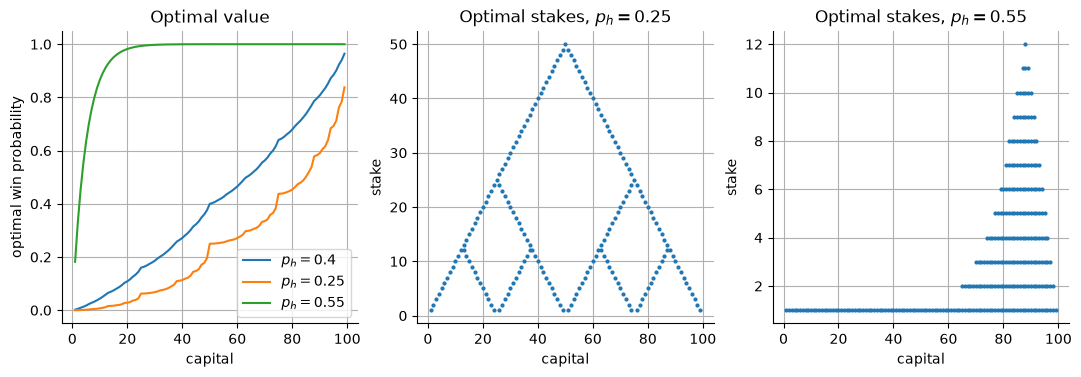

In [15]:
def bold_policy() -> np.ndarray:
    """Stake everything that can matter: min(capital, 100 - capital), as a one-hot policy matrix."""
    pi = np.zeros((GOAL + 1, GOAL // 2 + 1))
    pi[np.arange(1, GOAL), np.minimum(np.arange(1, GOAL), GOAL - np.arange(1, GOAL))] = 1.0
    pi[[0, GOAL], 0] = 1.0
    return pi


def timid_value(p_heads: float) -> np.ndarray:
    """Win probability of staking 1 dollar every time, in closed form (gambler's ruin)."""
    s, ratio = np.arange(GOAL + 1), (1 - p_heads) / p_heads
    return (1 - ratio**s) / (1 - ratio**GOAL)


nonterminal_B = np.ones(GOAL + 1, bool)
nonterminal_B[[0, GOAL]] = False
bold_checks = {}
for p, (P_p, R_p, valid_p) in GAMBLER.items():
    V_p, _, _, optimal_stakes = solved[p]
    v_bold = solve_policy(P_p, R_p, bold_policy(), 1.0, nonterminal_B)
    bold_always_optimal = bool(optimal_stakes[np.arange(GOAL - 1), np.minimum(np.arange(1, GOAL), GOAL - np.arange(1, GOAL))].all())
    bold_checks[p] = (np.abs(v_bold - V_p).max(), bold_always_optimal, np.abs(timid_value(p) - V_p)[1:GOAL].max())
    print(f"p_h = {p}: bold play differs from v_* by up to {bold_checks[p][0]:.1e}, is among the optimal stakes in every state: {bold_always_optimal}; "
          f"timid play (stake 1) differs from v_* by up to {bold_checks[p][2]:.1e}")
V_55, stakes_55 = solved[0.55][0], solved[0.55][3]
beyond_one = np.flatnonzero(stakes_55[:, 2:].any(axis=1)) + 1
print(f"p_h = 0.55: a stake above 1 lies within {TIE_TOL} of the best at {len(beyond_one)} capitals (from capital {beyond_one.min()} up); there 1 - v_* is at most {(1 - V_55[beyond_one]).max():.1e}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for p in P_HEADS:
    axes[0].plot(range(1, GOAL), solved[p][0][1:GOAL], label=f"$p_h = {p}$")
axes[0].set(xlabel="capital", ylabel="optimal win probability", title="Optimal value")
axes[0].legend()
for ax, p in zip(axes[1:], (0.25, 0.55)):
    caps, stakes = np.nonzero(solved[p][3])
    ax.plot(caps + 1, stakes, ".", ms=4)
    ax.set(xlabel="capital", ylabel="stake", title=f"Optimal stakes, $p_h = {p}$")
plt.show()

### Reading the result

- At $p_h = 0.4$ and $0.25$ staking as much as can matter (bold play) is optimal: its value differs from $v_*$ by $2.2 \times 10^{-11}$ and $6.5 \times 10^{-12}$, and its stake is among the optimal stakes in every state. Staking 1 dollar each time (timid play) is far worse, losing up to 0.80 and 0.73 in win probability.
- At $p_h = 0.55$ the game favors the gambler: staking 1 dollar each time matches its closed-form win probability to $9.0 \times 10^{-9}$ and bold play loses up to 0.75. Value iteration needs 1838 sweeps here, against 19 and 16, because winning takes a long run of small stakes.
- The left plot orders the three games as expected: more favorable coins give higher win probabilities everywhere, with $v_*(50)$ equal to 0.25, 0.40 and 1.00.
- In the right plot for $p_h = 0.55$ the dots above stake 1 appear from capital 65 up, at 34 capitals. There $1 - v_*$ is at most $2.2 \times 10^{-6}$ and stakes differ in value by less than the tie tolerance $10^{-7}$, so they are near-ties from rounding scale, not real alternatives; stake 1 is the optimal one throughout.

## 6. Asynchronous dynamic programming

Asynchronous DP is in-place DP that backs up states in any order, with no sweeps.
The only requirement is that no state is ignored forever; some may be backed up many times before others are backed up once.
We count how many single-state backups each scheme needs before the Bellman residual falls below `RESIDUAL_TOL`, so that sweeps and sweepless schemes are compared on the same footing (sweep schemes check the residual once per sweep, so their counts can overshoot by less than one sweep):

- **two-array sweeps**: every state backed up from the untouched old values;
- **in-place sweeps**, in increasing and in decreasing order of capital;
- **random states**: one uniformly random state per backup;
- **largest error first**: always back up the state whose value is currently the most inconsistent with its backup.

The gambler's problem with $p_h = 0.4$ is the test bed; policy evaluation on the gridworld gets the two-array versus in-place comparison.
That problem is undiscounted and episodic, where the book warns that some backup orders may fail to converge; the orders used here do converge.
Largest-error-first is this notebook's own illustration of choosing states cleverly, not a scheme from the chapter.

In [16]:
def backups_to_converge(P, R, valid, gamma, tol, kind: str, states: np.ndarray, rng=None) -> int:
    """Single-state backups of `kind` until the Bellman residual is below `tol`."""
    V, count = np.zeros(len(R)), 0
    while True:
        target = optimal_backup(V, P, R, valid, gamma)
        error = np.abs(target - V)[states]
        if error.max() < tol:
            return count
        if kind == "largest error first":
            V[states[error.argmax()]], count = target[states[error.argmax()]], count + 1
            continue
        if kind == "two-array sweeps":
            V[states] = target[states]
            count += len(states)
            continue
        sequence = rng.choice(states, len(states)) if kind == "random states" else states[:: -1 if kind == "in-place decreasing" else 1]
        for s in sequence:
            V[s] = backup_state(s, V, P, R, valid, gamma)
        count += len(states)

In [17]:
P_4, R_4, valid_4 = GAMBLER[0.4]
rng = np.random.default_rng(SEED_ASYNC)
interior = np.arange(1, GOAL)
async_counts = {}
for kind in ("two-array sweeps", "in-place increasing", "in-place decreasing", "random states", "largest error first"):
    runs = N_RANDOM_RUNS if kind == "random states" else 1
    async_counts[kind] = float(np.mean([backups_to_converge(P_4, R_4, valid_4, 1.0, RESIDUAL_TOL, kind, interior, rng) for _ in range(runs)]))
print(f"{'scheme':<22}{'backups':>10}{'sweeps-equivalent':>20}")
for kind, count in async_counts.items():
    print(f"{kind:<22}{count:>10.0f}{count / len(interior):>20.1f}")

sweeps_two_array = evaluate_policy(P_G, R_G, RANDOM_G, 1.0, THETA_COARSE)[1]
sweeps_in_place = evaluate_policy(P_G, R_G, RANDOM_G, 1.0, THETA_COARSE, in_place=True)[1]
sweeps_in_place_reverse = evaluate_policy(P_G, R_G, RANDOM_G, 1.0, THETA_COARSE, in_place=True, order=np.arange(15, -1, -1))[1]
print(f"\nGridworld policy evaluation to largest change below {THETA_COARSE}: two-array {sweeps_two_array} sweeps, in place {sweeps_in_place}, in place in reverse order {sweeps_in_place_reverse}")
print("Checkpoint: in-place sweeps need fewer backups than two-array sweeps in both examples:",
      async_counts["in-place increasing"] < async_counts["two-array sweeps"] and sweeps_in_place < sweeps_two_array)
print("Checkpoint: backing up the largest error first needs fewer backups than any sweep scheme:",
      async_counts["largest error first"] < min(v for k, v in async_counts.items() if "sweeps" in k or "in-place" in k))

scheme                   backups   sweeps-equivalent
two-array sweeps            2574                26.0
in-place increasing         1386                14.0
in-place decreasing         1485                15.0
random states               1723                17.4
largest error first          277                 2.8

Gridworld policy evaluation to largest change below 0.0001: two-array 173 sweeps, in place 114, in place in reverse order 114
Checkpoint: in-place sweeps need fewer backups than two-array sweeps in both examples: True
Checkpoint: backing up the largest error first needs fewer backups than any sweep scheme: True


### Reading the result

- In-place sweeps need 1386 backups (14 sweeps' worth) in increasing and 1485 in decreasing capital order, against 2574 (26 sweeps) for two-array sweeps: using fresh values immediately nearly halves the work here. Gridworld policy evaluation shows the same gain, 114 sweeps in place (in either order) against 173.
- Random single-state backups need 1723 on average over 5 runs: better than two-array sweeps (2574) but worse than in-place sweeps (1386 and 1485). No state is ignored, but nothing is aimed either.
- Backing up the state with the largest error first needs only 277 backups (2.8 sweeps' worth), because value information is spent where it still matters.
- These counts do not include the work of finding the largest error: the rule above computes every state's error before each backup, so its saving is in backups, not in total computation. Asynchronous schemes pay off when that choice is cheap or when only some states matter.

## 7. Generalized policy iteration

Policy evaluation pulls the values toward the current policy's values; policy improvement pulls the policy toward greediness with respect to the current values.
**Generalized policy iteration** (GPI) is any interleaving of the two, whatever their granularity.
The processes settle only when the policy is greedy for its own values, which is the Bellman optimality condition.

We run **truncated policy iteration** on Jack's car rental: improve greedily, then do exactly $m$ evaluation sweeps of the improved policy, and repeat.
Full policy iteration needs roughly 100 to 250 sweeps per evaluation (section 4), so $m = 50$ is already truncated; $m = 1$ is the same recursion as value iteration.

- **Cost**: the greedy improvement uses the same lookahead as the next backup, so a round is counted as $m$ sweeps. As a check that the ranking is not an artifact of this accounting, a second count charges one extra pass per round for the improvement.
- **Errors** tracked against the optimum $v_*$ and $q_*$: the value error $\max_s \lvert V(s) - v_*(s) \rvert$, and the policy gap $\max_s \big(v_*(s) - q_*(s, \pi(s))\big)$, which is zero exactly when the policy is optimal (ties allowed).

In [18]:
def truncated_policy_iteration(P: np.ndarray, R: np.ndarray, valid: np.ndarray, gamma: float, m: int, v_star: np.ndarray, max_sweeps: int):
    """Improve, then run `m` evaluation sweeps, until `max_sweeps`; returns (V, rows of (sweeps, value error, policy gap, rounds))."""
    rows, q_star = np.arange(len(R)), q_values(v_star, P, R, gamma)
    V, rounds, trace = np.zeros(len(R)), 0, []
    while rounds * m < max_sweeps:
        acts = greedy_mask(q_values(V, P, R, gamma), valid).argmax(axis=1)
        P_pi, R_pi = P[rows, acts], R[rows, acts]
        for _ in range(m):
            V = R_pi + gamma * P_pi @ V
        rounds += 1
        trace.append((rounds * m, np.abs(V - v_star).max(), (v_star - q_star[rows, acts]).max(), rounds))
    return V, np.array(trace)


def first_reached(trace: np.ndarray, column: int, tol: float):
    """(sweeps, sweeps plus one pass per round) when the traced error in `column` first falls below `tol`, or None."""
    below = trace[:, column] < tol
    if not below.any():
        return None
    row = trace[below.argmax()]
    return int(row[0]), int(row[0] + row[3])


gpi = {m: truncated_policy_iteration(P_J, R_J, VALID_J, GAMMA_JACK, m, V_PI_J, MAX_SWEEPS) for m in GPI_M}
V_vi_rounds = np.zeros(441)
for _ in range(gpi[1][1][-1, 0].astype(int)):
    V_vi_rounds = optimal_backup(V_vi_rounds, P_J, R_J, VALID_J, GAMMA_JACK)
print(f"Consistency check: the m = 1 code path and the value-iteration code path implement the same operator; after {MAX_SWEEPS} sweeps their values differ by {np.abs(gpi[1][0] - V_vi_rounds).max():.1e}")
print("Each entry: (evaluation sweeps, evaluation sweeps plus one pass per round for the improvement)")
print(f"{'m':>3}{'value error < ' + str(SMALL_ERROR):>26}{'optimal policy':>22}")
gpi_reach = {}
for m, (_, trace) in gpi.items():
    gpi_reach[m] = (first_reached(trace, 1, SMALL_ERROR), first_reached(trace, 2, POLICY_GAP_TOL))
    print(f"{m:>3}{str(gpi_reach[m][0]):>26}{str(gpi_reach[m][1]):>22}")

Consistency check: the m = 1 code path and the value-iteration code path implement the same operator; after 400 sweeps their values differ by 3.4e-13
Each entry: (evaluation sweeps, evaluation sweeps plus one pass per round for the improvement)
  m        value error < 0.01        optimal policy
  1                (103, 206)              (32, 64)
  3                (105, 140)              (36, 48)
 10                (110, 121)              (50, 55)
 50                (150, 153)            (150, 153)


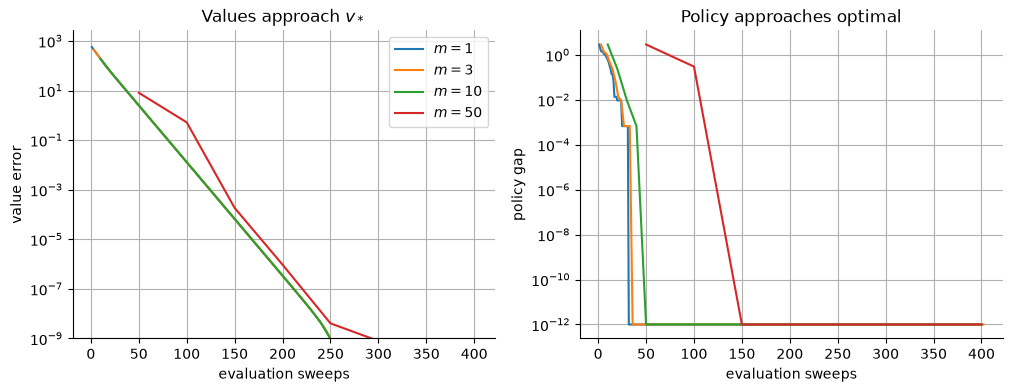

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m, (_, trace) in gpi.items():
    axes[0].semilogy(trace[:, 0], np.maximum(trace[:, 1], 1e-12), label=f"$m = {m}$")
    axes[1].semilogy(trace[:, 0], np.maximum(trace[:, 2], 1e-12), label=f"$m = {m}$")
axes[0].set(xlabel="evaluation sweeps", ylabel="value error", title="Values approach $v_*$", ylim=(1e-9, None))
axes[1].set(xlabel="evaluation sweeps", ylabel="policy gap", title="Policy approaches optimal")
axes[0].legend()
plt.show()

### Reading the result

- Counting only evaluation sweeps (the improvement folded into the next backup), the small values are fastest: an optimal policy appears after 32 sweeps for $m = 1$, 36 for $m = 3$, 50 for $m = 10$ and 150 for $m = 50$, and the value error falls below 0.01 after 103, 105, 110 and 150 sweeps.
- Charging one extra pass per round for the improvement changes the ranking: the optimal policy then takes 64, 48, 55 and 153 passes, and the value error needs 206, 140, 121 and 153. A moderate $m$ looks best under that accounting, so which $m$ is fastest depends on what the improvement costs; the notebook does not settle it.
- Policy iteration proper would use hundreds of sweeps per round (section 4); $m = 50$ is still truncated, and its policy turns optimal only after the third round of 50 sweeps.
- The left plot shows the value error shrinking geometrically for all $m$ (the rate is set by $\gamma$ per sweep); it levels off near $10^{-9}$ because the reference $v_*$ itself is only accurate to about that.
- The right plot shows the policy becoming optimal long before the values do: GPI does not need accurate values, only values good enough for the greedy choice to be right.
- The $m = 1$ code path and value iteration agree to $3.4 \times 10^{-13}$ after 400 sweeps. This only checks that two implementations compute the same recursion; it is not independent evidence.

## 8. Checkpoints

In [20]:
v_m1_gap = float(np.abs(gpi[1][0] - V_vi_rounds).max())
checks = [
    ("gridworld sweeps converge to the exact linear solve", np.abs(grid_values["limit"] - exact_G).max() < AGREE_TOL),
    ("gridworld v_1, v_2, v_3, v_10 and the limit match the book's grids to its printed precision", all(g < BOOK_TOL for g in gaps.values())),
    ("simulated steps to termination equal -v_pi", all(abs(v) < Z_MAX for v in z)),
    ("the greedy policy is not optimal for v_0, v_1, v_2 and is optimal for v_3 and v_10", not any(optimal_after[k] for k in (0, 1, 2)) and all(optimal_after[k] for k in (3, 10))),
    ("one improvement of the exact random-policy values is optimal", improved_is_optimal),
    ("Jack's car rental: policy iteration and value iteration agree on v_*", gap_pi_vi < AGREE_TOL),
    ("Jack's car rental: Bellman residual of v_* is near zero", residual_pi < AGREE_TOL),
    ("Jack's car rental: policy iteration finds its stable policy after 4 improvements (5 policies in all)", len(policies_J) == 5),
    ("gambler: Bellman residual near zero for every p_h", all(bellman_residual(solved[p][0], *GAMBLER[p], 1.0) < AGREE_TOL for p in P_HEADS)),
    ("gambler: bold play is optimal for p_h = 0.4 and 0.25", all(bold_checks[p][0] < AGREE_TOL and bold_checks[p][1] for p in (0.4, 0.25))),
    ("gambler: staking 1 matches the closed form and is optimal for p_h = 0.55", bold_checks[0.55][2] < 100 * AGREE_TOL),
    ("gambler: the optimal policy at p_h = 0.4 is not unique", all(v > 0 for v in ties_by_tol.values())),
    ("asynchronous: in-place beats two-array; largest-error-first beats every sweep scheme", sweeps_in_place < sweeps_two_array and async_counts["largest error first"] < async_counts["in-place increasing"] < async_counts["two-array sweeps"]),
    ("the m = 1 code path and the value-iteration code path implement the same operator (consistency, not independent evidence)", v_m1_gap < AGREE_TOL),
    ("truncated policy iteration reaches an optimal policy for every m", all(v[1] is not None for v in gpi_reach.values())),
]
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)

print("\nRows 1, 2, 5 and 6 have an exact reference (linear solve, expected steps, all-in stake, closed form); rows 3 and 4 only another algorithm's answer.")
print(f"{'method':<76}{'result':>10}{'reference':>10}")
for name, result, truth in [
    ("gridworld limit, cell 3 (reference: linear solve)", grid_values["limit"][3], exact_G[3]),
    ("gridworld simulated steps, cell 3 (reference: -v_pi)", steps[2].mean(), -exact_G[3]),
    ("Jack: v_* at (20, 20) by policy iteration (reference: value iteration)", V_PI_J[-1], V_VI_J[-1]),
    ("Jack: v_* at (0, 0) by policy iteration (reference: value iteration)", V_PI_J[0], V_VI_J[0]),
    ("gambler p_h=0.4: v_*(50) (reference: p_h, all-in stake)", solved[0.4][0][50], 0.4),
    ("gambler p_h=0.55: v_*(1) (reference: closed form)", solved[0.55][0][1], timid_value(0.55)[1]),
]:
    print(f"{name:<76}{result:>10.4f}{truth:>10.4f}")

PASS gridworld sweeps converge to the exact linear solve
PASS gridworld v_1, v_2, v_3, v_10 and the limit match the book's grids to its printed precision
PASS simulated steps to termination equal -v_pi
PASS the greedy policy is not optimal for v_0, v_1, v_2 and is optimal for v_3 and v_10
PASS one improvement of the exact random-policy values is optimal
PASS Jack's car rental: policy iteration and value iteration agree on v_*
PASS Jack's car rental: Bellman residual of v_* is near zero
PASS Jack's car rental: policy iteration finds its stable policy after 4 improvements (5 policies in all)
PASS gambler: Bellman residual near zero for every p_h
PASS gambler: bold play is optimal for p_h = 0.4 and 0.25
PASS gambler: staking 1 matches the closed form and is optimal for p_h = 0.55
PASS gambler: the optimal policy at p_h = 0.4 is not unique
PASS asynchronous: in-place beats two-array; largest-error-first beats every sweep scheme
PASS the m = 1 code path and the value-iteration code path imp